## 1. Đọc và tiền xử lý dữ liệu từ file data.csv

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, classification_report

In [4]:
df = pd.read_csv('data/animal.csv')
# Xóa các dòng bị trống dữ liệu ở cột nhãn (Dangerous) để tránh lỗi
df = df.dropna(subset=['Dangerous'])
# Chuyển đổi toàn bộ dữ liệu dạng chữ (String) sang dạng số (Numeric) 
le = LabelEncoder()
for col in df.columns:
    df[col] = le.fit_transform(df[col])
# Phân tách Đặc trưng (X) và Nhãn dự đoán (y)
X = df.drop('Dangerous', axis=1)
y = df['Dangerous']
# Chia tập dữ liệu Train/Test theo tỷ lệ 80/20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## 2. Xây dựng và Huấn luyện mô hình SVM

In [5]:
svc = SVC(random_state=42)
svc.fit(X_train, y_train)

# Tiến hành dự đoán trên tập kiểm thử
y_pred = svc.predict(X_test)

## 3. Vẽ Ma trận nhầm lẫn (Confusion Matrix - Heatmap)

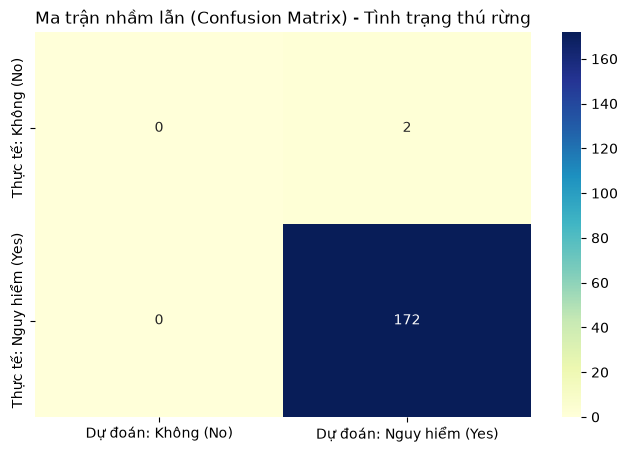

In [6]:
cm = confusion_matrix(y_test, y_pred)

# Đưa ma trận vào DataFrame để gán nhãn đẹp hơn (0: No, 1: Yes)
conf_matrix = pd.DataFrame(
    data=cm, 
    index=['Thực tế: Không (No)', 'Thực tế: Nguy hiểm (Yes)'], 
    columns=['Dự đoán: Không (No)', 'Dự đoán: Nguy hiểm (Yes)']
)

plt.figure(figsize=(8, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap="YlGnBu")
plt.title("Ma trận nhầm lẫn (Confusion Matrix) - Tình trạng thú rừng")
plt.show()

In [7]:
print("Báo cáo phân loại chi tiết (Classification Report):\n")
# zero_division=0 dùng để ẩn cảnh báo khi tập dữ liệu bị lệch (nhãn 'No' quá ít)
print(classification_report(y_test, y_pred, target_names=['Không (No)', 'Nguy hiểm (Yes)'], zero_division=0))

Báo cáo phân loại chi tiết (Classification Report):

                 precision    recall  f1-score   support

     Không (No)       0.00      0.00      0.00         2
Nguy hiểm (Yes)       0.99      1.00      0.99       172

       accuracy                           0.99       174
      macro avg       0.49      0.50      0.50       174
   weighted avg       0.98      0.99      0.98       174

